<a href="https://colab.research.google.com/github/dymiyata/wva-ml-ai-1-2026-2027/blob/main/train_test_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train Test Split and Model Comparison

First we import the usual libraries and modules

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

Let's create some synthetic data:

In [ ]:
# Setting the random seed
rng = np.random.default_rng(seed=2025)

m = 100
x1 = np.linspace(0, 20, m)[:, np.newaxis]

y = 0.2 * x1**2 - 3 * x1 + 20 + 4*rng.standard_normal((m, 1))

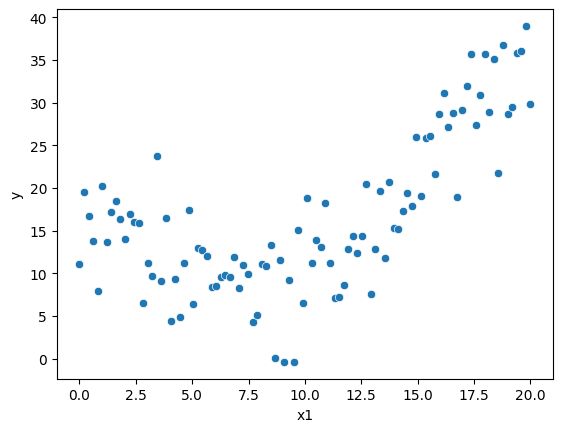

In [ ]:
sns.scatterplot(x = x1[:,0], y = y[:,0])
plt.xlabel("x1")
plt.ylabel("y")
plt.show()

Scikit-learn has a function `train_test_split` to spilt our data into a training set and testing set. To use it, we first need to import it.

In [ ]:
from sklearn.model_selection import train_test_split

Now we can use it to automatically randomly split our data into two sets:
- A training set (used to train the models)
- A testing set (used to evaluate how the model generalizes)

The `train_test_split` function let's you select what proportion of the data will be used for testing. The rest will be put in the training set. A good rule of thumb is to use about 80\% of your data for training and 20\% of the data for testing.

In [ ]:
x1_train, x1_test, y_train, y_test = train_test_split(
    x1,
    y,
    test_size=0.2,
    random_state=2026
)

In [ ]:
print(x1.shape)
print(y.shape)
print(x1_train.shape)
print(y_train.shape)
print(x1_test.shape)
print(y_test.shape)

(100, 1)
(100, 1)
(80, 1)
(80, 1)
(20, 1)
(20, 1)


Now let's create four different models (degree 1, degree 2, degree 3, and degree 15).

To ensure that the features stay roughly the same size, we normalize them.

In [ ]:
model1 = LinearRegression()
model2 = LinearRegression()
model3 = LinearRegression()
model15 = LinearRegression()

In [ ]:
# Create feature matrix for each model
# Scale features so they're similar sizes
x_train1 = x1_train
x_train2 = np.column_stack([x1_train, 0.1 * x1_train ** 2])
x_train3 = np.column_stack([x1_train, 0.1 * x1_train ** 2, 0.1 ** 2 * x1_train ** 3])
x_train15 = np.column_stack([0.1 ** (i-1) * x1_train ** i for i in range(1, 16)])



In [ ]:
x_test1 = x1_test
x_test2 = np.column_stack([x1_test, 0.1 * x1_test ** 2])
x_test3 = np.column_stack([x1_test, 0.1 * x1_test ** 2, 0.1 ** 2 * x1_test ** 3])
x_test15 = np.column_stack([0.1 ** (i-1) * x1_test ** i for i in range(1, 16)])

In [ ]:
model1.fit(x_train1, y_train)
model2.fit(x_train2, y_train)
model3.fit(x_train3, y_train)
model15.fit(x_train15, y_train)

LinearRegression()

In [ ]:
y_pred_train1 = model1.predict(x_train1)
y_pred_train2 = model2.predict(x_train2)
y_pred_train3 = model3.predict(x_train3)
y_pred_train15 = model15.predict(x_train15)

In [ ]:
y_pred_test1 = model1.predict(x_test1)
y_pred_test2 = model2.predict(x_test2)
y_pred_test3 = model3.predict(x_test3)
y_pred_test15 = model15.predict(x_test15)

In [ ]:
mse1_train = mean_squared_error(y_train, y_pred_train1)
mse2_train = mean_squared_error(y_train, y_pred_train2)
mse3_train = mean_squared_error(y_train, y_pred_train3)
mse15_train = mean_squared_error(y_train, y_pred_train15)

In [ ]:
mse1_test = mean_squared_error(y_test, y_pred_test1)
mse2_test = mean_squared_error(y_test, y_pred_test2)
mse3_test = mean_squared_error(y_test, y_pred_test3)
mse15_test = mean_squared_error(y_test, y_pred_test15)

In [ ]:
for mse in [mse1_train, mse2_train, mse3_train, mse15_train]:
    print(mse)

46.35339756004045
21.759136562151895
21.655802903960005
17.9769353694833


In [ ]:
for mse in [mse1_test, mse2_test, mse3_test, mse15_test]:
    print(mse)

59.71299895721775
15.2408567496641
15.434207182680382
20.620924709555844


Based on this we would say degree 2 is the best with degree 3 being a close second.

Degree 1 seems to be underfitting.

Degree 15 seems to be overfitting because it does well on training but poor on testing.